# Supervised Learning: Multiple Linear Regression (UCI Wine Quality)

Notebook ini merupakan versi mandiri (*standalone*) dari pipeline **Supervised Learning (Linear Regression)** agar dapat dijalankan langsung secara terpisah di **Google Colab** maupun **Jupyter lokal** tanpa bergantung pada modul internal repositori.

### Apa yang dipelajari & dilakukan di notebook ini?
1. **Load & Validasi Dataset** (otomatis mendeteksi dataset lokal atau mengunduh dari UCI Machine Learning Repository jika dijalankan di Colab).
2. **Exploratory Data Analysis (EDA)**: statistik deskriptif, matriks korelasi antar fitur, dan distribusi skor `quality`.
3. **Preprocessing Bebas *Data Leakage***: `train_test_split` terlebih dahulu, lalu `SimpleImputer(strategy="median")` + `StandardScaler()` di dalam `sklearn.pipeline.Pipeline`.
4. **Pelatihan Model**: *Multiple Linear Regression* (*Ordinary Least Squares*) menggunakan `scikit-learn`.
5. **Evaluasi & Diagnostik**: MAE, MSE, RMSE, $R^2$, plot Aktual vs Prediksi, analisis residual, serta interpretasi koefisien fitur terstandarisasi.
6. **Ekspor Artefak**: menyimpan model (`.joblib`), metrik (`metrics.json`), tabel koefisien, prediksi uji, dan grafik PNG.

## 1. Penjelasan Singkat Algoritma & Dataset

### Multiple Linear Regression
Model memprediksi variabel target kontinu $y$ (`quality`) sebagai kombinasi linear dari seluruh fitur input $x_1, x_2, \dots, x_p$:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$

- Karena memakai **11 fitur fisikokimia sekaligus** (bukan hanya 1 fitur), metode ini disebut **Multiple Linear Regression** (Regresi Linear Berganda).
- Nilai $\beta_i$ dicari menggunakan metode **Ordinary Least Squares (OLS)** yang meminimalkan jumlah kuadrat galat (*Residual Sum of Squares*).
- Dengan menambahkan `StandardScaler()` sebelum `LinearRegression()`, besar koefisien $\beta_i$ menjadi **sebanding antar fitur** (dalam satuan standar deviasi), sehingga memudahkan kita melihat fitur mana yang paling berpengaruh.

### Dataset: UCI Wine Quality
Dataset berisi sifat fisikokimia sampel wine (pemisah titik koma `;`):
`fixed acidity`, `volatile acidity`, `citric acid`, `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide`, `density`, `pH`, `sulphates`, `alcohol`, dan target `quality` (skor bilangan bulat).

In [10]:
# ==========================================
# 1. Import Library & Pengaturan Tampilan
# ==========================================
from datetime import datetime, timezone
import json
from pathlib import Path
from typing import Optional, Union
import urllib.request

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

print("Semua library berhasil dimuat.")

Semua library berhasil dimuat.


## 2. Konfigurasi Eksperimen

Ubah parameter di bawah ini sesuai kebutuhan eksperimen:
- `WINE_VARIANT`: pilih `"white"` (`winequality-white.csv`, 4.898 baris) atau `"red"` (`winequality-red.csv`, 1.599 baris).
- `CUSTOM_CSV_PATH`: isi path CSV jika ingin memakai file sendiri (mis. hasil upload ke Colab `/content/nama_file.csv`), atau biarkan `None` untuk deteksi lokal / unduh otomatis dari UCI.
- `TARGET_COL`: nama kolom target yang akan diprediksi (default: `"quality"`).
- `TEST_SIZE`: proporsi data uji (default: `0.2` = 80% train, 20% test).
- `RANDOM_STATE`: seed acak agar hasil split selalu konsisten / *reproducible*.
- `SAVE_ARTIFACTS`: jika `True`, semua grafik PNG, CSV, `metrics.json`, dan `.joblib` disimpan ke `OUTPUT_DIR`.

In [11]:
# ==========================================
# 2. Konfigurasi Parameter Eksperimen
# ==========================================
WINE_VARIANT = "white"       # Pilihan: "white" atau "red"
CUSTOM_CSV_PATH = None       # Contoh di Colab: "/content/winequality-red.csv"
TARGET_COL = "quality"
TEST_SIZE = 0.2
RANDOM_STATE = 42

SAVE_ARTIFACTS = True
OUTPUT_DIR = Path("outputs/linear_regression")

if not (0 < TEST_SIZE < 1):
    raise ValueError("TEST_SIZE harus lebih besar dari 0 dan kurang dari 1.")
if WINE_VARIANT not in {"white", "red"}:
    raise ValueError("WINE_VARIANT harus 'white' atau 'red'.")

## 3. Load & Validasi Dataset (Siap Jalan di Colab & Lokal)

Fungsi di bawah ini akan mencari dataset secara berurutan:
1. Jika `CUSTOM_CSV_PATH` diisi, pakai file tersebut.
2. Jika file ada di folder proyek (`data/wine-quality/...` atau `../data/wine-quality/...`), pakai file lokal.
3. Jika belum ada (misalnya baru membuka notebook ini di **Google Colab**), notebook otomatis mengunduh file resmi dari **UCI Machine Learning Repository** ke `./data/wine-quality/`.

> **Tips Colab:** Jika ingin upload CSV dari komputer sendiri, jalankan di sel baru:
> ```python
> from google.colab import files
> uploaded = files.upload()
> ```
> lalu isi `CUSTOM_CSV_PATH = list(uploaded.keys())[0]`.

In [12]:
# ==========================================
# 3. Helper Download & Load Dataset Wine Quality
# ==========================================
UCI_URLS = {
    "white": "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv",
    "red": "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",
}


def resolve_or_download_wine_csv(
    variant: str, custom_path: Optional[Union[str, Path]] = None
) -> Path:
    if custom_path is not None:
        path = Path(custom_path)
        if not path.is_file():
            raise FileNotFoundError(f"File custom tidak ditemukan: {path}")
        return path.resolve()

    filename = f"winequality-{variant}.csv"
    local_candidates = [
        Path("data/wine-quality") / filename,
        Path("../data/wine-quality") / filename,
        Path("wine+quality") / filename,
        Path("../wine+quality") / filename,
    ]
    for candidate in local_candidates:
        if candidate.is_file():
            print(f"Menggunakan dataset lokal: {candidate.resolve()}")
            return candidate.resolve()

    target_path = Path("data/wine-quality") / filename
    target_path.parent.mkdir(parents=True, exist_ok=True)
    url = UCI_URLS[variant]
    print(f"Dataset lokal tidak ditemukan. Mengunduh dari UCI Repository:\n{url}")
    urllib.request.urlretrieve(url, target_path)
    print(f"Dataset berhasil diunduh ke: {target_path.resolve()}")
    return target_path.resolve()


def load_wine_dataset(
    data_path: Path,
    target_column: str,
    *,
    drop_missing_target: bool = True,
    min_rows: int = 3,
) -> tuple:
    # Dataset UCI Wine Quality memakai pemisah titik koma (;)
    frame = pd.read_csv(data_path, sep=";")
    frame.columns = frame.columns.str.strip()

    if frame.empty:
        raise ValueError("Dataset kosong.")
    if target_column not in frame.columns:
        raise ValueError(
            f"Kolom target '{target_column}' tidak ditemukan. Kolom tersedia: {', '.join(frame.columns)}"
        )

    frame[target_column] = pd.to_numeric(frame[target_column], errors="coerce")
    if drop_missing_target:
        missing_count = int(frame[target_column].isna().sum())
        if missing_count:
            print(f"Menghapus {missing_count} baris dengan target kosong/tidak valid.")
            frame = frame.dropna(subset=[target_column]).copy()

    features = frame.drop(columns=target_column)
    non_numeric = features.select_dtypes(exclude=np.number).columns.tolist()
    if non_numeric:
        raise ValueError(f"Semua fitur harus numerik. Ditemukan kolom non-numerik: {', '.join(non_numeric)}")
    if features.shape[1] == 0:
        raise ValueError("Dataset tidak memiliki fitur untuk diproses.")
    if len(frame) < min_rows:
        raise ValueError(f"Dataset membutuhkan minimal {min_rows} baris valid.")

    return features, frame[target_column].rename(target_column)


data_path = resolve_or_download_wine_csv(WINE_VARIANT, CUSTOM_CSV_PATH)
features, target = load_wine_dataset(data_path, TARGET_COL, drop_missing_target=True)

print(f"Jumlah baris valid : {len(features)}")
print(f"Jumlah fitur       : {features.shape[1]}")
print(f"Daftar fitur       : {list(features.columns)}")
print("\nMissing values per kolom:")
print(features.isna().sum())

display(pd.concat([features, target], axis=1).head())

Menggunakan dataset lokal: /Users/muhammadwildan/Programming/kuliah/mechine-learning-project/data/wine-quality/winequality-white.csv
Jumlah baris valid : 4898
Jumlah fitur       : 11
Daftar fitur       : ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Missing values per kolom:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


## 4. Exploratory Data Analysis (EDA)

Sebelum melatih model, kita memeriksa:
1. **Statistik Deskriptif (`describe()`)**: rata-rata, standar deviasi, nilai minimum, kuartil, dan maksimum untuk melihat perbedaan skala antar fitur (misalnya `total sulfur dioxide` bernilai ratusan sedangkan `density` berada di sekitar `0.99`).
2. **Matriks Korelasi**: melihat hubungan linear antar fitur maupun antara setiap fitur dengan target `quality` (waspadai juga *multikolinearitas*, misalnya hubungan kuat antara `density`, `residual sugar`, dan `alcohol`).
3. **Distribusi Target `quality`**: melihat sebaran skor kualitas wine (umumnya terkonsentrasi di skor 5, 6, dan 7).

Ringkasan Statistik Deskriptif:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,4898.0,6.8548,0.8439,3.8000,6.3000,6.8000,7.3000,14.200
volatile acidity,4898.0,0.2782,0.1008,0.0800,0.2100,0.2600,0.3200,1.100
citric acid,4898.0,0.3342,0.1210,0.0000,0.2700,0.3200,0.3900,1.660
residual sugar,4898.0,6.3914,5.0721,0.6000,1.7000,5.2000,9.9000,65.800
chlorides,4898.0,0.0458,0.0218,0.0090,0.0360,0.0430,0.0500,0.346
free sulfur dioxide,4898.0,35.3081,17.0071,2.0000,23.0000,34.0000,46.0000,289.000
total sulfur dioxide,4898.0,138.3607,42.4981,9.0000,108.0000,134.0000,167.0000,440.000
density,4898.0,0.9940,0.0030,0.9871,0.9917,0.9937,0.9961,1.039
pH,4898.0,3.1883,0.1510,2.7200,3.0900,3.1800,3.2800,3.820
sulphates,4898.0,0.4898,0.1141,0.2200,0.4100,0.4700,0.5500,1.080



Korelasi Pearson fitur terhadap target quality:


,correlation_with_quality
alcohol,0.4356
pH,0.0994
sulphates,0.0537
free sulfur dioxide,0.0082
citric acid,-0.0092
residual sugar,-0.0976
fixed acidity,-0.1137
total sulfur dioxide,-0.1747
volatile acidity,-0.1947
chlorides,-0.2099


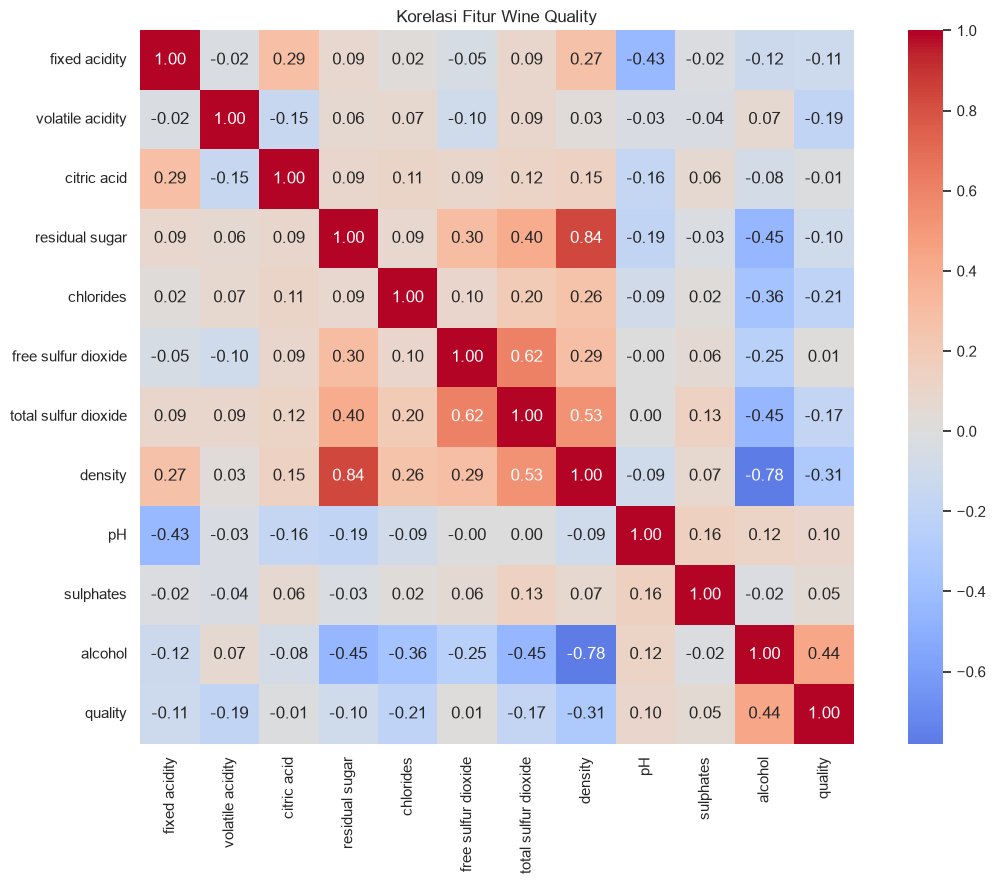

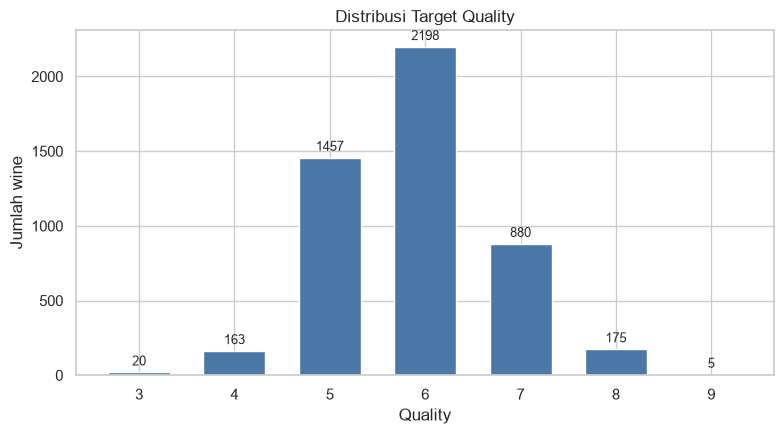

In [13]:
# ==========================================
# 4. EDA: Statistik Deskriptif, Korelasi, & Distribusi Target
# ==========================================
if SAVE_ARTIFACTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

eda_frame = features.copy()
eda_frame[target.name] = target

eda_summary = eda_frame.describe().T
if SAVE_ARTIFACTS:
    eda_summary.to_csv(OUTPUT_DIR / "eda_summary.csv")

print("Ringkasan Statistik Deskriptif:")
display(eda_summary)

# Korelasi fitur terhadap target
target_corr = eda_frame.corr(numeric_only=True)[TARGET_COL].drop(TARGET_COL).sort_values(ascending=False)
print("\nKorelasi Pearson fitur terhadap target quality:")
display(target_corr.to_frame(name="correlation_with_quality"))

# Plot 1: Correlation Matrix Heatmap
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(eda_frame.corr(numeric_only=True), cmap="coolwarm", center=0, annot=True, fmt=".2f", square=True, ax=ax)
ax.set_title("Korelasi Fitur Wine Quality")
fig.tight_layout()
if SAVE_ARTIFACTS:
    fig.savefig(OUTPUT_DIR / "correlation_matrix.png", dpi=160)
plt.show()

# Plot 2: Distribusi Target Quality
target_counts = target.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(target_counts.index.astype(str), target_counts.values, color="#4C78A8", width=0.65)
ax.bar_label(bars, padding=3, fontsize=9)
ax.set(xlabel="Quality", ylabel="Jumlah wine")
ax.set_title("Distribusi Target Quality")
fig.tight_layout()
if SAVE_ARTIFACTS:
    fig.savefig(OUTPUT_DIR / "target_distribution.png", dpi=160)
plt.show()

## 5. Train/Test Split & Pipeline Preprocessing (Bebas *Data Leakage*)

Mengapa kita membungkus `SimpleImputer` dan `StandardScaler` di dalam `sklearn.pipeline.Pipeline` **setelah** `train_test_split`?
- Jika kita menghitung median (`SimpleImputer`) atau mean/standar deviasi (`StandardScaler`) memakai keseluruhan dataset **sebelum** split, informasi dari data uji (*test set*) akan bocor ke proses pelatihan (*data leakage*).
- Dengan `Pipeline`:
  1. `pipeline.fit(x_train, y_train)` hanya mempelajari median dan mean/std dari **data latih (`x_train`)**.
  2. `pipeline.predict(x_test)` otomatis menerapkan parameter median & scaler dari data latih ke **data uji (`x_test`)**.

Langkah di dalam pipeline:
1. `SimpleImputer(strategy="median")` — mengisi nilai kosong (jika ada) dengan median fitur.
2. `StandardScaler()` — menstandarisasi fitur ke mean = 0 dan std = 1 ($z = \frac{x - \mu}{\sigma}$).
3. `LinearRegression()` — melatih regresi linear berganda (OLS).

In [14]:
# ==========================================
# 5. Train/Test Split & Training Pipeline
# ==========================================
x_train, x_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]
)

pipeline.fit(x_train, y_train)
predictions = pipeline.predict(x_test)

print(f"Jumlah data latih (train) : {len(x_train)}")
print(f"Jumlah data uji (test)    : {len(x_test)}")
print(f"Intercept (bias) model    : {pipeline.named_steps['model'].intercept_:.4f}")

Jumlah data latih (train) : 3918
Jumlah data uji (test)    : 980
Intercept (bias) model    : 5.8714


## 6. Evaluasi Model Regresi

Untuk menilai performa prediksi pada data uji (`x_test`), kita menghitung metrik berikut:
- **MAE (*Mean Absolute Error*)**: rata-rata selisih absolut $|y - \hat{y}|$. Mudah diinterpretasikan langsung dalam satuan skor `quality`.
- **MSE (*Mean Squared Error*)**: rata-rata kuadrat galat $(y - \hat{y})^2$; memberi penalti lebih besar pada kesalahan prediksi yang jauh.
- **RMSE (*Root Mean Squared Error*)**: akar dari MSE ($\sqrt{\text{MSE}}$), kembali ke satuan asli skor `quality`.
- **$R^2$ (*Coefficient of Determination*)**: proporsi variasi target `quality` yang mampu dijelaskan oleh model linear (`1.0` = sempurna, `0.0` = setara menebak rata-rata). Pada dataset Wine Quality, nilai $R^2$ regresi linear murni biasanya moderat (~0.25–0.36) karena hubungan antar variabel fisikokimia dan penilaian sensorik manusia bersifat kompleks/non-linear.
- **Mean Residual**: rata-rata $(y - \hat{y})$; nilai mendekati `0` menandakan prediksi tidak bias secara sistematis (tidak terlalu tinggi atau terlalu rendah secara rata-rata).

In [15]:
# ==========================================
# 6. Hitung Metrik Evaluasi & Tabel Prediksi
# ==========================================
actual_array = y_test.to_numpy()
residuals = actual_array - predictions
mse = float(mean_squared_error(actual_array, predictions))

metrics = {
    "dataset": str(data_path),
    "target": TARGET_COL,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "train_samples": int(len(x_train)),
    "test_samples": int(len(x_test)),
    "feature_count": int(features.shape[1]),
    "mae": float(mean_absolute_error(actual_array, predictions)),
    "mse": mse,
    "rmse": float(np.sqrt(mse)),
    "r2": float(r2_score(actual_array, predictions)),
    "mean_actual_quality": float(y_test.mean()),
    "mean_predicted_quality": float(np.mean(predictions)),
    "mean_residual": float(np.mean(residuals)),
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
}

print(json.dumps(metrics, indent=2))

predictions_df = pd.DataFrame(
    {
        "row_index": x_test.index,
        "actual_quality": actual_array,
        "predicted_quality": predictions,
        "residual": residuals,
    }
)

if SAVE_ARTIFACTS:
    predictions_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
    with (OUTPUT_DIR / "metrics.json").open("w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2)

print("\nContoh 10 hasil prediksi pada data uji:")
display(predictions_df.head(10))

{
  "dataset": "/Users/muhammadwildan/Programming/kuliah/mechine-learning-project/data/wine-quality/winequality-white.csv",
  "target": "quality",
  "random_state": 42,
  "test_size": 0.2,
  "train_samples": 3918,
  "test_samples": 980,
  "feature_count": 11,
  "mae": 0.5862665383250466,
  "mse": 0.5690247717229253,
  "rmse": 0.7543373063311434,
  "r2": 0.2652750042179156,
  "mean_actual_quality": 5.904081632653061,
  "mean_predicted_quality": 5.893188435116162,
  "mean_residual": 0.010893197536898888,
  "created_at_utc": "2026-11-18T11:41:34.552154+00:00"
}

Contoh 10 hasil prediksi pada data uji:


,row_index,actual_quality,predicted_quality,residual
0,4656,7,6.3718,0.6282
1,3659,8,6.3982,1.6018
2,907,8,6.4118,1.5882
3,4352,5,5.8298,-0.8298
4,3271,7,6.4375,0.5625
5,4632,6,6.3667,-0.3667
6,2244,5,5.2376,-0.2376
7,1924,4,5.4803,-1.4803
8,3801,6,6.0853,-0.0853
9,2634,5,5.3294,-0.3294


## 7. Visualisasi Diagnostik Hasil Prediksi

Tiga grafik berikut membantu memeriksa kualitas prediksi model regresi:
1. **Aktual vs Prediksi**: titik yang makin dekat ke garis putus-putus merah menandakan prediksi makin akurat. Karena `quality` berupa bilangan bulat (3–9) sedangkan output regresi linear kontinu, titik-titik aktual akan tampak membentuk garis vertikal per nilai integer.
2. **Residual terhadap Prediksi**: idealnya titik tersebar acak di sekitar garis horizontal `0` tanpa pola melengkung atau corong (*homoskedastisitas*).
3. **Distribusi Residual**: idealnya berbentuk lonceng simetris (*bell-shaped*) berpusat di `0`.

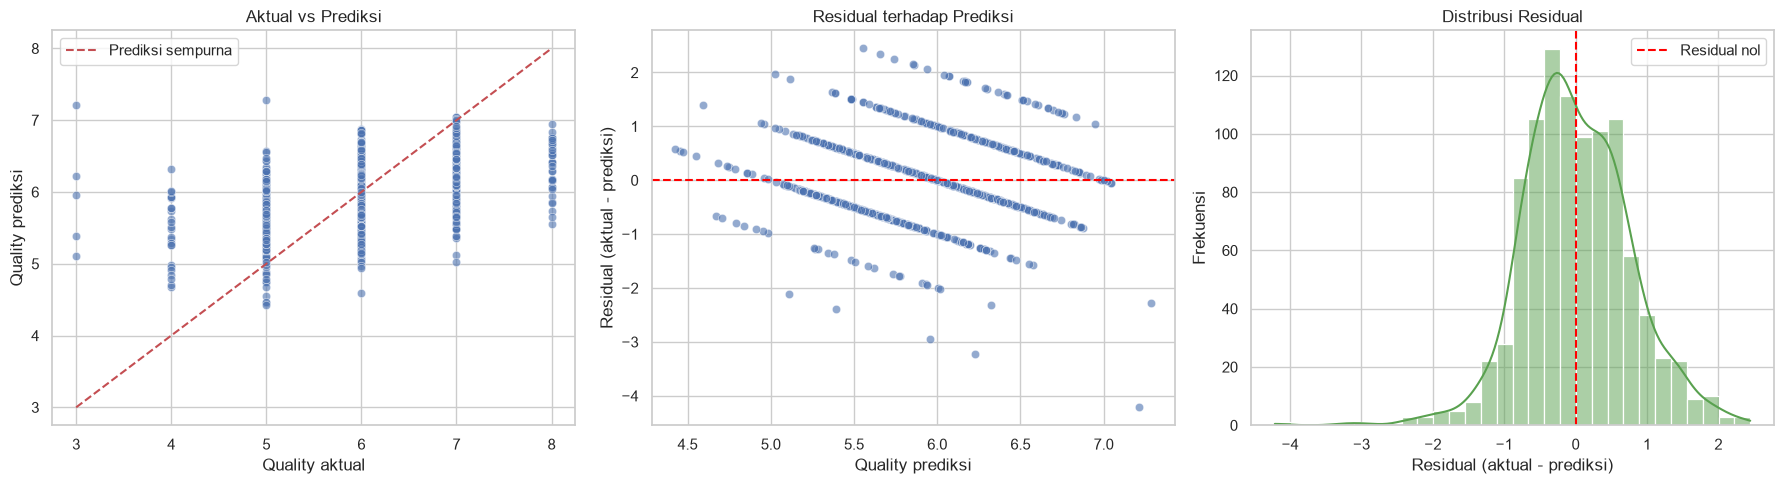

In [16]:
# ==========================================
# 7. Plot Diagnostik Prediksi & Residual
# ==========================================
lower = float(min(actual_array.min(), predictions.min()))
upper = float(max(actual_array.max(), predictions.max()))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Actual vs Predicted
sns.scatterplot(x=actual_array, y=predictions, alpha=0.6, ax=axes[0])
axes[0].plot([lower, upper], [lower, upper], "r--", label="Prediksi sempurna")
axes[0].set(xlabel="Quality aktual", ylabel="Quality prediksi", title="Aktual vs Prediksi")
axes[0].legend()

# 2. Residual vs Predicted
sns.scatterplot(x=predictions, y=residuals, alpha=0.6, ax=axes[1])
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(xlabel="Quality prediksi", ylabel="Residual (aktual - prediksi)", title="Residual terhadap Prediksi")

# 3. Residual Distribution
sns.histplot(residuals, bins=30, kde=True, color="#59A14F", ax=axes[2])
axes[2].axvline(0, color="red", linestyle="--", label="Residual nol")
axes[2].set(xlabel="Residual (aktual - prediksi)", ylabel="Frekuensi", title="Distribusi Residual")
axes[2].legend()

fig.tight_layout()
plt.show()

# Simpan masing-masing file PNG terpisah agar konsisten dengan artefak pipeline
if SAVE_ARTIFACTS:
    for name, draw_fn in [
        ("actual_vs_predicted.png", lambda ax: (
            sns.scatterplot(x=actual_array, y=predictions, alpha=0.65, ax=ax),
            ax.plot([lower, upper], [lower, upper], "r--", label="Prediksi sempurna"),
            ax.set(xlabel="Quality aktual", ylabel="Quality prediksi", title="Aktual vs Prediksi"),
            ax.legend(),
        )),
        ("residual_plot.png", lambda ax: (
            sns.scatterplot(x=predictions, y=residuals, alpha=0.65, ax=ax),
            ax.axhline(0, color="red", linestyle="--"),
            ax.set(xlabel="Quality prediksi", ylabel="Residual (aktual - prediksi)", title="Residual terhadap Prediksi"),
        )),
        ("residual_distribution.png", lambda ax: (
            sns.histplot(residuals, bins=30, kde=True, color="#59A14F", ax=ax),
            ax.axvline(0, color="red", linestyle="--", label="Residual nol"),
            ax.set(xlabel="Residual (aktual - prediksi)", ylabel="Frekuensi", title="Distribusi Residual"),
            ax.legend(),
        )),
    ]:
        f_single, ax_single = plt.subplots(figsize=(7, 5.5))
        draw_fn(ax_single)
        f_single.tight_layout()
        f_single.savefig(OUTPUT_DIR / name, dpi=160)
        plt.close(f_single)

## 8. Interpretasi Koefisien Fitur (*Feature Importance*)

Karena seluruh fitur sudah melewati `StandardScaler()`, nilai koefisien (`standardized_coefficient`) menunjukkan **seberapa besar perubahan skor prediksi `quality` jika suatu fitur naik sebesar 1 standar deviasi** (dengan fitur lain dianggap tetap):
- **Koefisien positif (biru)**: kenaikan fitur cenderung **menaikkan** prediksi kualitas (contoh umumnya `alcohol` dan `residual sugar` pada white wine).
- **Koefisien negatif (merah)**: kenaikan fitur cenderung **menurunkan** prediksi kualitas (contoh umumnya `volatile acidity` atau `density` saat variabel lain dikontrol).

> **Catatan penting:** Ketika ada dua fitur yang berkorelasi kuat (misalnya `density`, `residual sugar`, dan `alcohol`), koefisien regresi mencerminkan efek parsial masing-masing fitur *setelah mengontrol fitur lain*, sehingga tanda koefisiennya bisa berbeda dari korelasi Pearson tunggal.

,feature,standardized_coefficient,absolute_coefficient
7,density,-0.3754,0.3754
3,residual sugar,0.3661,0.3661
10,alcohol,0.2812,0.2812
1,volatile acidity,-0.1945,0.1945
8,pH,0.0902,0.0902
5,free sulfur dioxide,0.0854,0.0854
9,sulphates,0.0737,0.0737
0,fixed acidity,0.0388,0.0388
6,total sulfur dioxide,-0.0102,0.0102
2,citric acid,-0.0073,0.0073


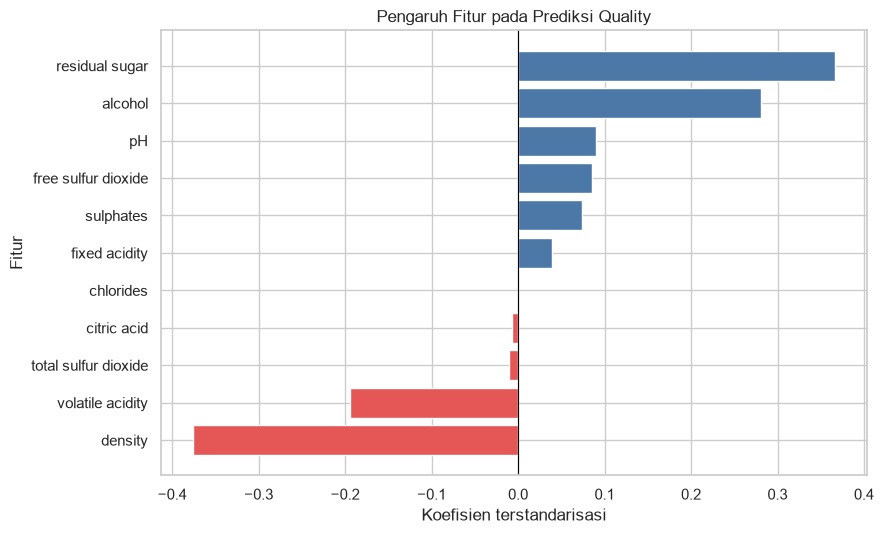

Semua artefak berhasil disimpan di: /Users/muhammadwildan/Programming/kuliah/mechine-learning-project/notebook/outputs/linear_regression


In [17]:
# ==========================================
# 8. Tabel & Grafik Koefisien Terstandarisasi + Simpan Model
# ==========================================
regression_model = pipeline.named_steps["model"]
coefficients = pd.DataFrame(
    {
        "feature": features.columns,
        "standardized_coefficient": regression_model.coef_,
        "absolute_coefficient": np.abs(regression_model.coef_),
    }
).sort_values("absolute_coefficient", ascending=False)

display(coefficients)

plot_data = coefficients.sort_values("standardized_coefficient")
colors = np.where(plot_data["standardized_coefficient"] >= 0, "#4C78A8", "#E45756")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(plot_data["feature"], plot_data["standardized_coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Koefisien terstandarisasi", ylabel="Fitur", title="Pengaruh Fitur pada Prediksi Quality")
fig.tight_layout()
if SAVE_ARTIFACTS:
    fig.savefig(OUTPUT_DIR / "feature_importance.png", dpi=160)
plt.show()

if SAVE_ARTIFACTS:
    coefficients.to_csv(OUTPUT_DIR / "coefficients.csv", index=False)
    joblib.dump(pipeline, OUTPUT_DIR / "linear_regression_pipeline.joblib")
    print(f"Semua artefak berhasil disimpan di: {OUTPUT_DIR.resolve()}")

## 9. Contoh Inferensi (Prediksi Sampel Baru)

Karena seluruh preprocessing (`SimpleImputer` + `StandardScaler`) dan model sudah tersimpan di dalam satu objek `Pipeline` (`linear_regression_pipeline.joblib`), kita cukup memanggil `.predict(dataframe_fitur)` secara langsung pada data baru tanpa perlu scaling manual lagi.

In [18]:
# ==========================================
# 9. Uji Prediksi pada Beberapa Sampel Data Baru
# ==========================================
loaded_pipeline = (
    joblib.load(OUTPUT_DIR / "linear_regression_pipeline.joblib")
    if SAVE_ARTIFACTS
    else pipeline
)

sample_features = x_test.iloc[:5]
sample_preds = loaded_pipeline.predict(sample_features)

preview_cols = list(features.columns[:4])
demo_result = sample_features[preview_cols].copy()
demo_result["actual_quality"] = y_test.iloc[:5].values
demo_result["predicted_quality"] = np.round(sample_preds, 3)
demo_result["error"] = np.round(demo_result["actual_quality"] - demo_result["predicted_quality"], 3)

display(demo_result)

,fixed acidity,volatile acidity,citric acid,residual sugar,actual_quality,predicted_quality,error
4656,6.0,0.29,0.41,10.8,7,6.372,0.628
3659,5.4,0.53,0.16,2.7,8,6.398,1.602
907,7.1,0.25,0.39,2.1,8,6.412,1.588
4352,7.3,0.28,0.35,1.6,5,5.830,-0.830
3271,6.5,0.32,0.34,5.7,7,6.438,0.562
